# 03 · Baselines

Before the LSTM, we need to know what "good" means. Four baselines, each one step smarter:

| Model | Prediction for ICHR's next hour |
|---|---|
| **Zero** | always 0, i.e. "unpredictable" |
| **Persistence** | ICHR's last-hour return repeats |
| **Ridge** | linear combination of the last 7 hours of all 10 tickers (70 inputs) |
| **Ridge + big moves** | same, plus the leaders' returns *only when they were big* (>2σ), so big moves get their own weight |

All models see the same input: a window of shape `(7 hours, n features)`, built in `features.py`.
The LSTM in step 4 gets exactly this window too.

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from semiconductor_affairs.baselines import Persistence, Zero, ridge
from semiconductor_affairs.data import load_close, log_returns
from semiconductor_affairs.evaluate import report, walk_forward, walk_forward_splits
from semiconductor_affairs.features import make_dataset
from semiconductor_affairs.ingest import TARGET

r = log_returns(load_close())
base = make_dataset(r, window=7)
big = make_dataset(r, window=7, with_big_moves=True)
assert (base.timestamps == big.timestamps).all()   # identical samples
print("X shape without / with big moves:", base.X.shape, big.X.shape)

X shape without / with big moves: (4217, 7, 10) (4217, 7, 17)


## Walk-forward splits
Train on everything before a cut-off, test on the next quarter, move the cut-off forward. **Every prediction comes from
a model that has only seen the past.** The training set grows each time (expanding window).
The first year (2024) is only ever used for training.

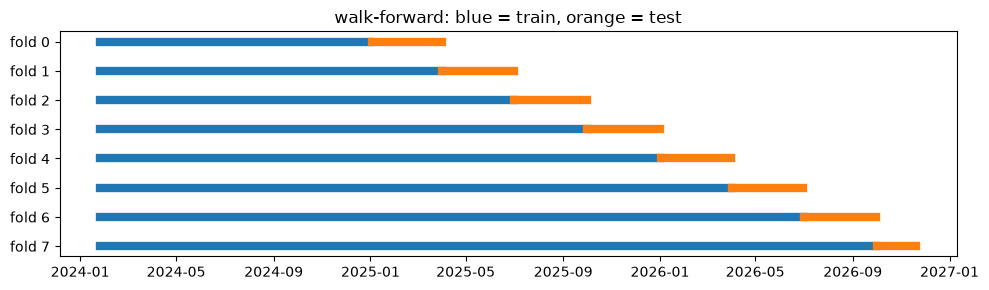

In [4]:
splits = walk_forward_splits(base.timestamps, first_test="2025-01-01", test_months=3)
ts = base.timestamps
fig, ax = plt.subplots(figsize=(10, 3))
for i, (train, test) in enumerate(splits):
    ax.plot([ts[train[0]], ts[train[-1]]], [i, i], color="tab:blue", lw=6)
    ax.plot([ts[test[0]], ts[test[-1]]], [i, i], color="tab:orange", lw=6)
ax.set_yticks(range(len(splits)), [f"fold {i}" for i in range(len(splits))])
ax.invert_yaxis()
ax.set_title("walk-forward: blue = train, orange = test")
plt.tight_layout()

## Run all baselines

In [5]:
target_col = base.feature_names.index(TARGET)
models = {
    "zero": (Zero, base),
    "persistence": (lambda: Persistence(target_col), base),
    "ridge": (ridge, base),
    "ridge + big moves": (ridge, big),
}
preds = {name: walk_forward(make, data, splits) for name, (make, data) in models.items()}

summary = pd.concat(
    {name: report(models[name][1], p, by="year") for name, p in preds.items()}
)
summary.round(3)

n  MAE %  RMSE %  skill vs zero %   corr  \
zero              2025  1488.0  0.821   1.141            0.000    NaN   
                  2026  1332.0  0.994   1.376            0.000    NaN   
                  all   2820.0  0.903   1.258            0.000    NaN   
persistence       2025  1488.0  1.491   2.490         -376.205  0.031   
                  2026  1332.0  1.858   2.961         -362.879 -0.061   
                  all   2820.0  1.664   2.723         -368.668 -0.019   
ridge             2025  1488.0  0.821   1.139            0.381  0.070   
                  2026  1332.0  0.996   1.379           -0.453 -0.016   
                  all   2820.0  0.904   1.258           -0.091  0.017   
ridge + big moves 2025  1488.0  0.821   1.138            0.456  0.070   
                  2026  1332.0  0.996   1.380           -0.564 -0.018   
                  all   2820.0  0.904   1.258           -0.121  0.021   

                        rank corr  direction acc %  
zero              2025        NaN              NaN  
                  2026        NaN              NaN  
                  all         NaN              NaN  
persistence       2025     -0.015           48.464  
                  2026     -0.014           50.151  
                  all      -0.015           49.266  
ridge             2025      0.042           51.126  
                  2026     -0.014           47.741  
                  all       0.015           49.517  
ridge + big moves 2025      0.030           50.512  
                  2026     -0.010           48.343  
                  all       0.014           49.481

### How to read the columns
- **MAE % / RMSE %**: average size of the miss (predicted − actual). RMSE punishes big misses more.
- **skill vs zero %**: `1 − MSE_model / MSE_zero`. **Positive = better than always guessing 0.** This is the key number.
- **corr / rank corr**: do larger predictions go together with larger actual moves?
- **direction acc %**: share of hours where the predicted sign (up/down) was right. 50% is a coin flip.

Zero has no direction or correlation (it never varies), so those are empty.

## Skill per quarter
One number for the whole test period hides the regime change from notebook 02. Per quarter:

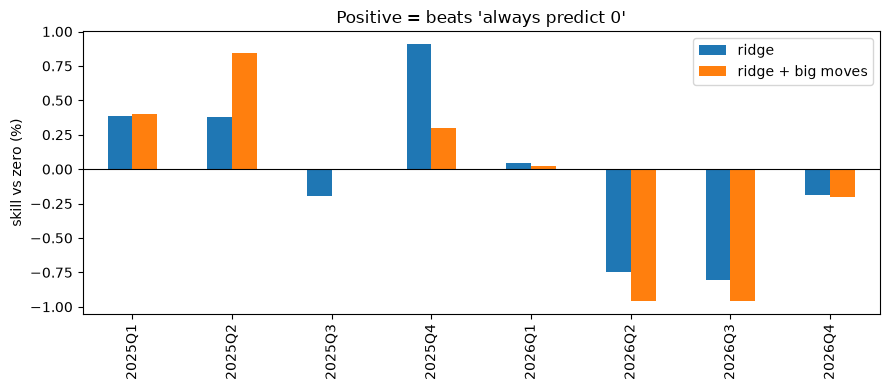

In [6]:
per_q = pd.DataFrame({
    name: report(models[name][1], p)["skill vs zero %"]
    for name, p in preds.items() if name not in ("zero", "persistence")
}).drop("all")
ax = per_q.plot.bar(figsize=(9, 4))
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("skill vs zero (%)")
ax.set_title("Positive = beats 'always predict 0'")
plt.tight_layout()

## Cumulative advantage over zero
Running sum of (squared error of zero − squared error of ridge). Rising = ridge is winning, falling = losing.
This shows *when* the model earns or loses its edge.

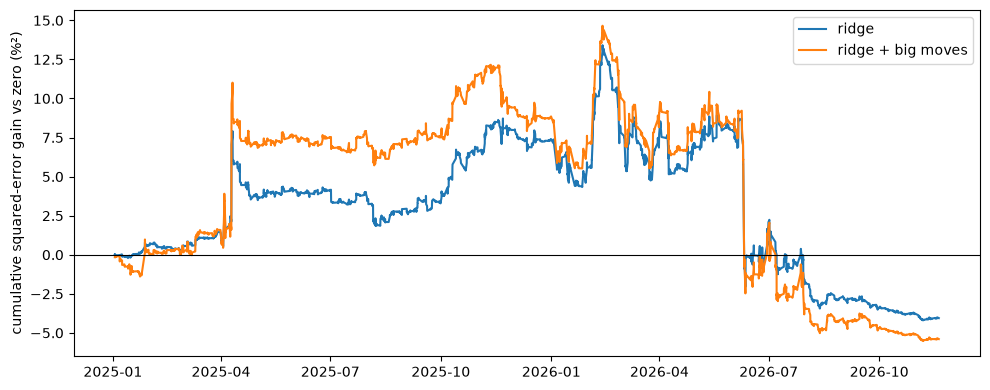

In [7]:
y = base.y
fig, ax = plt.subplots(figsize=(10, 4))
for name in ["ridge", "ridge + big moves"]:
    p = preds[name]
    gain = (y[p.index] ** 2 - (y[p.index] - p.to_numpy()) ** 2) * 1e4  # in %²
    ax.plot(ts[p.index], np.cumsum(gain), label=name)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("cumulative squared-error gain vs zero (%²)")
ax.legend()
plt.tight_layout()

## Predicted vs actual
The most honest picture. Watch the scales of the two axes.

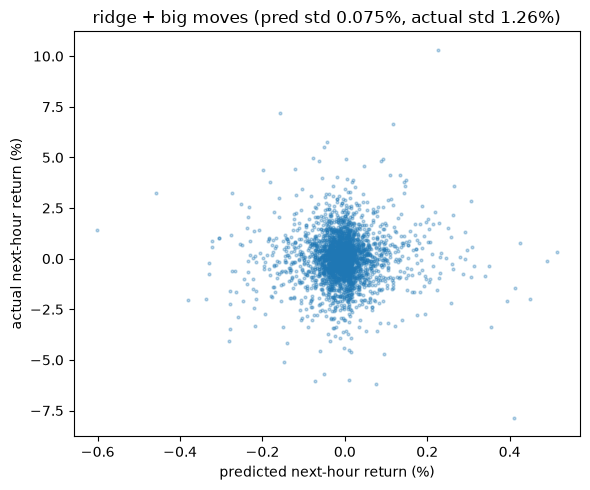

In [ ]:
p = preds["ridge + big moves"]
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(p * 100, y[p.index] * 100, s=4, alpha=0.3)
ax.set_xlabel("predicted next-hour return (%)")
ax.set_ylabel("actual next-hour return (%)")
ax.set_title(f"ridge + big moves (pred std {p.std()*100:.3f}%, actual std {y[p.index].std()*100:.2f}%)")
plt.tight_layout()

## What did ridge learn?
First: how strong a penalty (alpha) did ridge choose in each fold? A higher alpha pulls all weights harder towards 0.
The grid goes up to 1,000,000, which effectively means "use no inputs at all".

alpha per fold: ['10,000', '17,783', '10,000', '5,623', '10,000', '17,783', '31,623', '1,000,000']


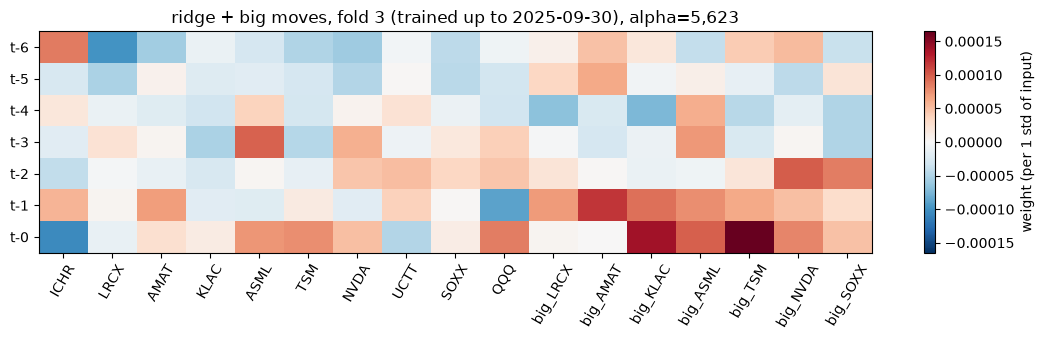

In [9]:
alphas = [ridge().fit(big.X[train], big.y[train])[-1].alpha_ for train, _ in splits]
print("alpha per fold:", [f"{a:,.0f}" for a in alphas])

fold = int(np.argmin(alphas))          # the fold where ridge trusted the inputs most
train, _ = splits[fold]
model = ridge().fit(big.X[train], big.y[train])
coef = model[-1].coef_.reshape(big.X.shape[1], big.X.shape[2])   # (window, features)
coef = pd.DataFrame(coef, columns=big.feature_names,
                    index=[f"t-{k}" for k in range(big.X.shape[1] - 1, -1, -1)])

lim = np.abs(coef.to_numpy()).max()
fig, ax = plt.subplots(figsize=(11, 3.5))
im = ax.imshow(coef, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(coef.shape[1]), coef.columns, rotation=60)
ax.set_yticks(range(coef.shape[0]), coef.index)
fig.colorbar(im, label="weight (per 1 std of input)")
ax.set_title(f"ridge + big moves, fold {fold} (trained up to {ts[train[-1]]:%Y-%m-%d}), alpha={alphas[fold]:,.0f}")
plt.tight_layout()

## Conclusions (2026-11-20)

1. **Nothing beats "always predict 0" over the whole test period.** Ridge: −0.09% skill, ridge + big moves: −0.12%.
   Direction accuracy ≈ 49.5%, a coin flip.
2. **Persistence is terrible (−370% skill).** Its predictions are as big as real moves, so every wrong guess doubles the
   error. Lesson: when the signal is weak, *small* predictions are the safe ones.
3. **Ridge protects itself by shrinking.** Its time-ordered CV picks a very strong penalty in every fold (alpha 5,600–31,600),
   and in the last fold the maximum (1,000,000), i.e. "ignore all inputs". Its predictions vary by only ~0.07% against
   actual moves of ~1.3%, which is why its MAE equals zero's.
   Where it does use inputs (fold 3), the weights are tiny (≤ 0.02% per std) and sit mostly on the last 1–2 hours:
   big moves in TSM/KLAC/AMAT push the prediction up, and ICHR's own last hour pushes it *down* (the bid-ask-bounce
   reversal). That matches notebook 02, but it's far too weak to predict with.
4. **The regime flip shows up exactly as in notebook 02.** 2025: small positive skill (+0.4%, corr 0.07). 2026: negative
   (−0.5%). The model learns "follow the market" from 2024–25, and that stops working in 2026.
5. **Big-move features didn't help.** The hint from notebook 02 isn't usable by a linear model, at least not this way.

**What this means for the LSTM:** the bar is "skill > 0 on the walk-forward, in *both* years". Realistically the LSTM
will also land near 0. The learning value is in seeing *why*: how it overfits, how regularisation pulls it to 0, and
whether its hidden state picks up the regime (which a fixed linear model can't).